# Pokémon classifier on real-world animals: a black-box analysis

**AI and Visualization · VIS4AI · Phase I**



## 1. Data and measurement definitions



In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown

CSV_PATH = Path('results_fg/fg_predictions.csv')
if not CSV_PATH.is_file():
    fallback = Path.home() / 'Desktop/pokemon-ood/results_fg/fg_predictions.csv'
    if fallback.is_file():
        CSV_PATH = fallback
    else:
        raise FileNotFoundError('Place this notebook in the pokemon-ood project root or change CSV_PATH.')

raw = pd.read_csv(CSV_PATH)
required = ['image_path','animal_category','predicted_pokemon','confidence',
            'normalized_entropy','top2_margin']
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f'Missing original result columns: {missing}. Found: {raw.columns.tolist()}')

df = raw.copy()
df['source_row'] = np.arange(len(df))
df['animal_category'] = df['animal_category'].astype('string').str.strip().str.casefold()
df['predicted_pokemon'] = df['predicted_pokemon'].astype('string').str.strip()
for c in ['confidence','normalized_entropy','top2_margin']:
    df[c] = pd.to_numeric(df[c],errors='coerce')
if df['confidence'].max() > 1 and df['confidence'].max() <= 100:
    df['confidence'] = df['confidence']/100
    if df['top2_margin'].max()>1:
        df['top2_margin'] = df['top2_margin']/100
df = df.dropna(subset=['animal_category','predicted_pokemon','confidence']).copy()
if not df['confidence'].between(0,1).all():
    raise ValueError('Confidence must be between 0 and 1.')
THRESHOLD = 0.70
df['high'] = df['confidence'] >= THRESHOLD
OUTDIR = CSV_PATH.parent / 'phaseI_final_report'
OUTDIR.mkdir(parents=True,exist_ok=True)
TARGET = {'cattle':'Bouffalant','antelope':'Sawsbuck'}

print('Dataset:',len(df),'images across',df['animal_category'].nunique(),'animal categories')
print('Model: imzynoxprince/pokemons-image-classifier-gen1-gen9')
print('Columns:',list(raw.columns))
print('High-confidence cases:',int(df['high'].sum()),'(',f'{df.high.mean():.2%}',')')
display(df[['image_path','animal_category','predicted_pokemon','confidence',
            'normalized_entropy','top2_margin']].head(3))


Dataset: 1800 images across 20 animal categories
Model: imzynoxprince/pokemons-image-classifier-gen1-gen9
Columns: ['image_name', 'image_id', 'image_path', 'animal_category', 'predicted_pokemon', 'confidence', 'entropy', 'normalized_entropy', 'second_pokemon', 'second_confidence', 'top2_margin']
High-confidence cases: 39 ( 2.17% )


,image_path,animal_category,predicted_pokemon,confidence,normalized_entropy,top2_margin
0,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...,alpaca,Zigzagoon,0.109345,0.748979,0.052327
1,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...,alpaca,Furfrou,0.050475,0.841184,0.006607
2,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...,alpaca,Muddy Goomy,0.043250,0.820509,0.008587


## 2. Global patterns



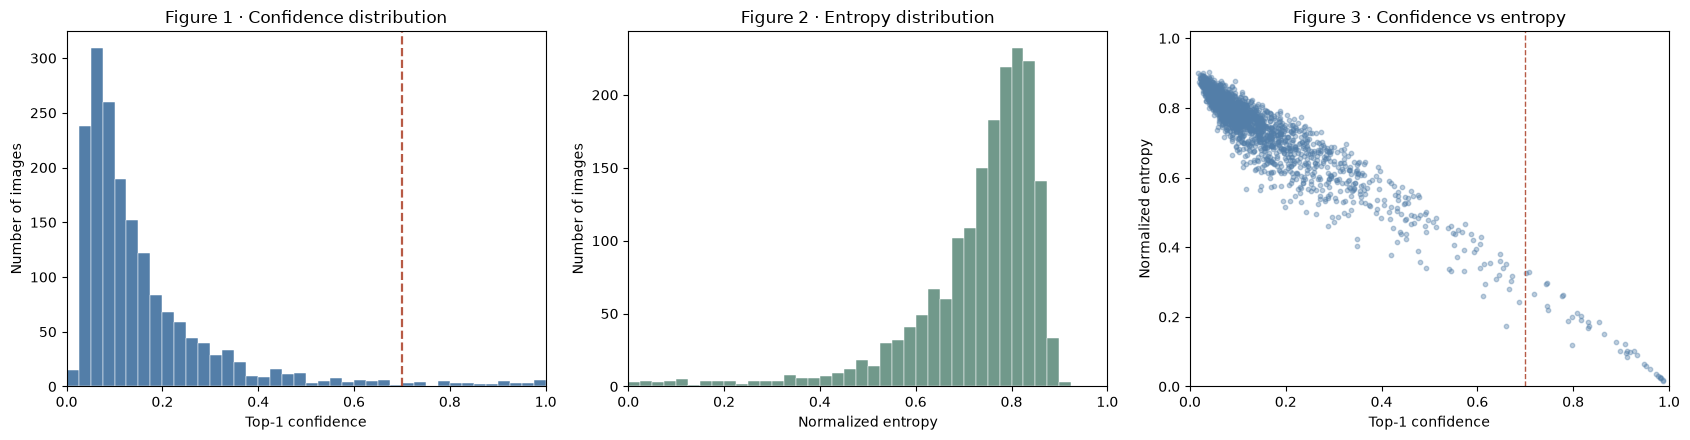

39 / 1800 = 2.17% exceed or equal 70% confidence
Global confidence median: 0.109; normalized entropy median: 0.770


In [2]:
fig, axs = plt.subplots(1,3,figsize=(17,4.5))
axs[0].hist(df['confidence'],bins=np.linspace(0,1,41),color='#537EA8',edgecolor='white',linewidth=.35)
axs[0].axvline(THRESHOLD,ls='--',color='#B75A45',lw=1.6)
axs[0].set(xlabel='Top-1 confidence',ylabel='Number of images',title='Figure 1 · Confidence distribution',xlim=(0,1))
axs[1].hist(df['normalized_entropy'].dropna(),bins=np.linspace(0,1,41),color='#71998B',edgecolor='white',linewidth=.35)
axs[1].set(xlabel='Normalized entropy',ylabel='Number of images',title='Figure 2 · Entropy distribution',xlim=(0,1))
axs[2].scatter(df['confidence'],df['normalized_entropy'],s=10,alpha=.38,color='#537EA8')
axs[2].axvline(THRESHOLD,ls='--',color='#B75A45',lw=1)
axs[2].set(xlabel='Top-1 confidence',ylabel='Normalized entropy',
           title='Figure 3 · Confidence vs entropy',xlim=(0,1),ylim=(0,1.02))
fig.tight_layout()
fig.savefig(OUTDIR/'01_global_distributions.png',dpi=180,bbox_inches='tight')
plt.show()
print(f'{int(df.high.sum())} / {len(df)} = {df.high.mean():.2%} exceed or equal 70% confidence')
print(f'Global confidence median: {df.confidence.median():.3f}; normalized entropy median: {df.normalized_entropy.median():.3f}')


## 3. From all images to animal categories



,n,high_n,median_conf,high_pct
animal_category,,,,
cattle,90,17,0.150,18.889
antelope,90,9,0.170,10.000
cat,90,4,0.206,4.444
dog,90,2,0.088,2.222
leopard,90,2,0.076,2.222
deer,90,1,0.155,1.111
elephant,90,1,0.078,1.111
kangaroo,90,1,0.177,1.111
monkey,90,1,0.120,1.111


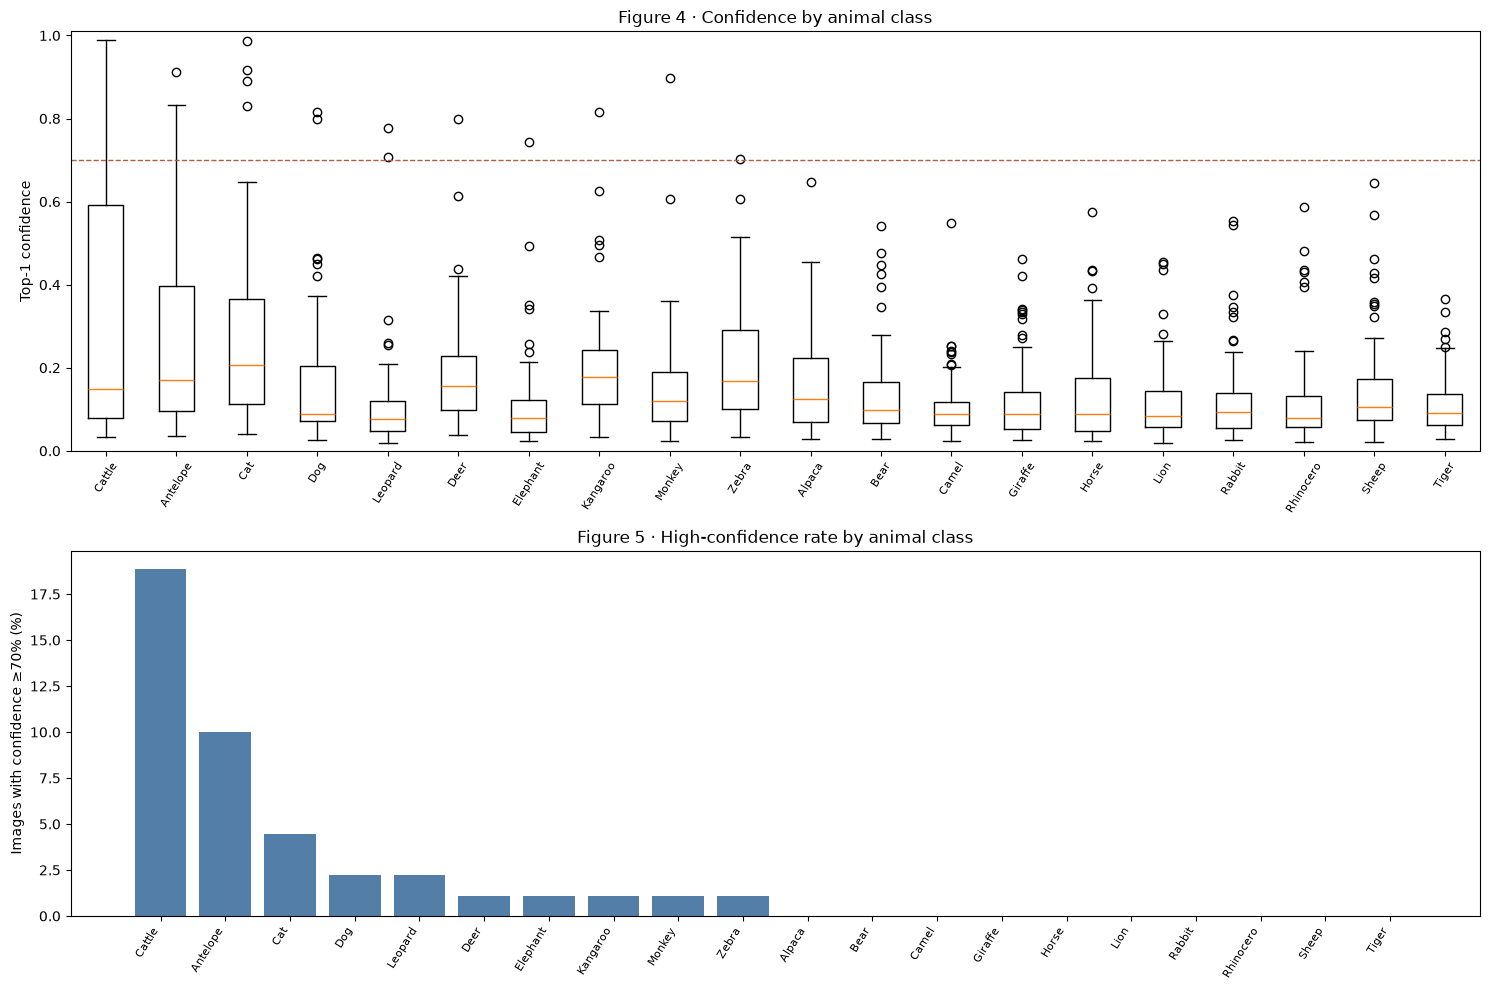

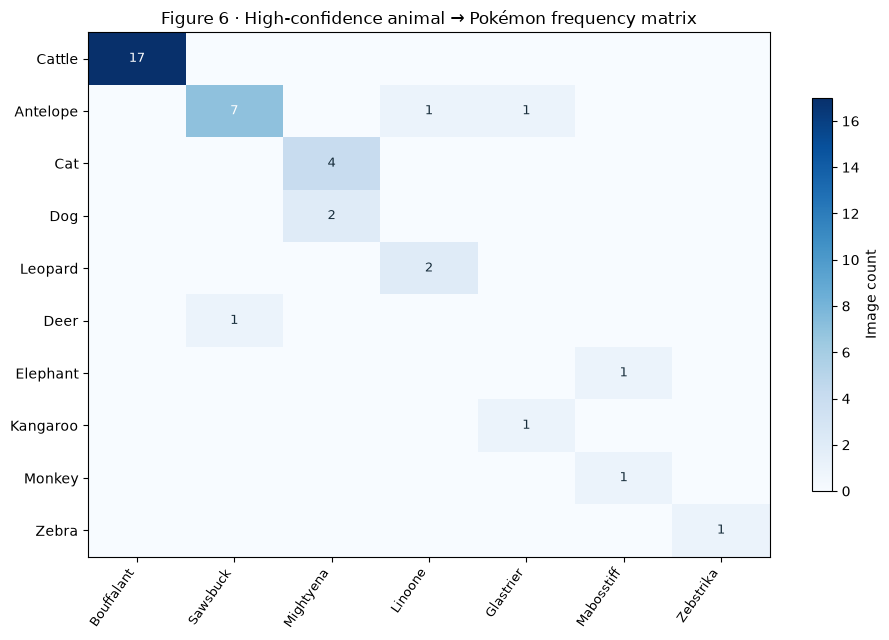

Most frequent high-confidence pairings:


images
animal_category predicted_pokemon        
cattle          Bouffalant             17
antelope        Sawsbuck                7
cat             Mightyena               4
dog             Mightyena               2
leopard         Linoone                 2
antelope        Glastrier               1
                Linoone                 1
deer            Sawsbuck                1
elephant        Mabosstiff              1
kangaroo        Glastrier               1
monkey          Mabosstiff              1
zebra           Zebstrika               1

In [3]:
group = (df.groupby('animal_category')
         .agg(n=('confidence','size'),high_n=('high','sum'),median_conf=('confidence','median')))
group['high_pct']=100*group['high_n']/group['n']
group=group.sort_values(['high_pct','high_n'],ascending=False)
display(group.round(3))
group.to_csv(OUTDIR/'02_animal_group_statistics.csv')

fig,axes=plt.subplots(2,1,figsize=(15,10),height_ratios=[1.15,1])
order=group.index.tolist()
axes[0].boxplot([df.loc[df.animal_category.eq(a),'confidence'].values for a in order],
                tick_labels=[a.title() for a in order],showfliers=True,patch_artist=False)
axes[0].axhline(THRESHOLD,color='#B75A45',ls='--',lw=1)
axes[0].set(ylabel='Top-1 confidence',title='Figure 4 · Confidence by animal class',ylim=(0,1.01))
axes[0].tick_params(axis='x',labelrotation=58,labelsize=8)
axes[1].bar(range(len(order)),group['high_pct'],color='#537EA8')
axes[1].set_xticks(range(len(order)),[a.title() for a in order],rotation=58,ha='right',fontsize=8)
axes[1].set(ylabel='Images with confidence ≥70% (%)',title='Figure 5 · High-confidence rate by animal class')
fig.tight_layout()
fig.savefig(OUTDIR/'02_animal_groups.png',dpi=180,bbox_inches='tight')
plt.show()

high=df[df.high]
mat=pd.crosstab(high['animal_category'],high['predicted_pokemon'])
mat=mat.loc[mat.sum(axis=1).sort_values(ascending=False).index,
            mat.sum(axis=0).sort_values(ascending=False).index]
fig,ax=plt.subplots(figsize=(max(9,0.8*len(mat.columns)+4),max(5,0.45*len(mat)+2)))
im=ax.imshow(mat.values,cmap='Blues',aspect='auto',vmin=0)
ax.set(xticks=range(len(mat.columns)),yticks=range(len(mat.index)),
       xticklabels=mat.columns,yticklabels=[x.title() for x in mat.index],
       title='Figure 6 · High-confidence animal → Pokémon frequency matrix')
plt.setp(ax.get_xticklabels(),rotation=55,ha='right',fontsize=9)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        if mat.iat[i,j]:
            ax.text(j,i,str(int(mat.iat[i,j])),ha='center',va='center',
                    fontsize=9,color='white' if mat.iat[i,j]>=7 else '#172D3B')
fig.colorbar(im,ax=ax,shrink=.75,label='Image count')
fig.tight_layout()
fig.savefig(OUTDIR/'03_high_confidence_matrix.png',dpi=180,bbox_inches='tight')
plt.show()
print('Most frequent high-confidence pairings:')
pairs=high.groupby(['animal_category','predicted_pokemon']).size().sort_values(ascending=False)
display(pairs.head(12).rename('images').to_frame())
pairs.to_csv(OUTDIR/'03_high_confidence_pairs.csv')


## 4. Within-group analysis: Cattle and Antelope




Cattle (n=90), most frequent predictions:


,below_70,at_least_70,total
predicted_pokemon,,,
Bouffalant,24,17,41
Tauros,5,0,5
Wyrdeer,5,0,5
Mabosstiff,4,0,4
Glastrier,3,0,3
Muddy Goomy,3,0,3
Ursaring,3,0,3
Dubwool,2,0,2
Greedent,2,0,2



Antelope (n=90), most frequent predictions:


,below_70,at_least_70,total
predicted_pokemon,,,
Sawsbuck,19,7,26
Glastrier,13,1,14
Wyrdeer,11,0,11
Linoone,4,1,5
Persian,5,0,5
Rapidash,5,0,5
Muddy Goomy,4,0,4
Thievul,2,0,2
Absol,1,0,1


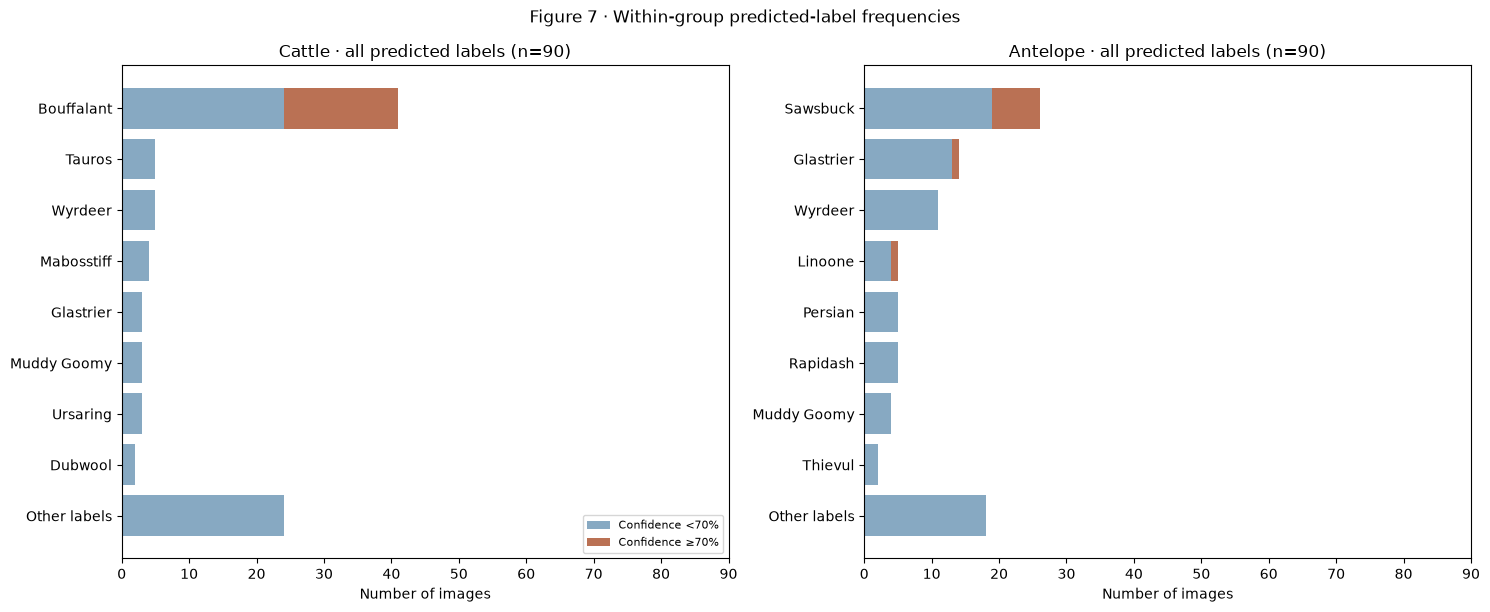

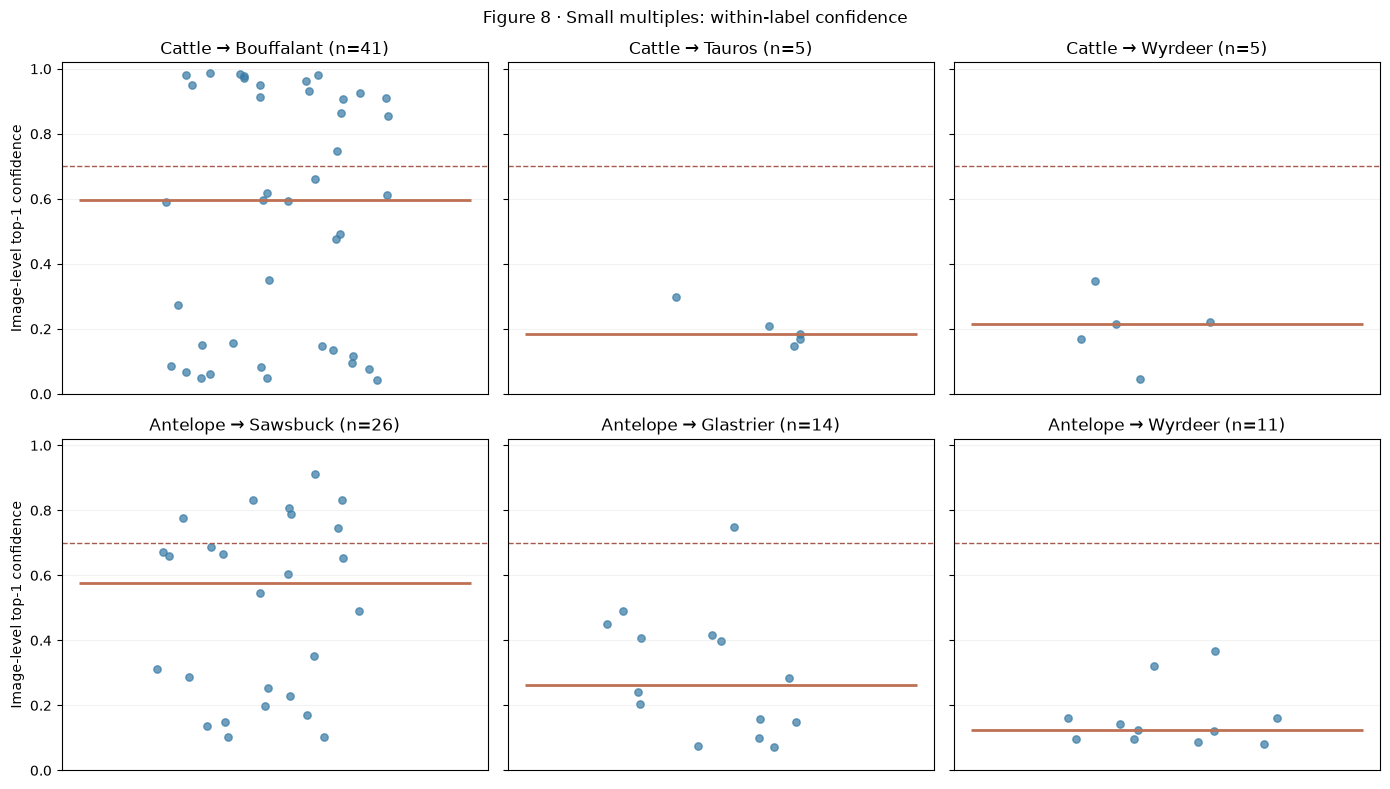

In [4]:
subsets={animal:df[df.animal_category.eq(animal)].copy() for animal in TARGET}
for a,part in subsets.items():
    if part.empty:raise ValueError(f'Animal group {a} was not found in the CSV')

tables={}
for animal,part in subsets.items():
    tab=pd.crosstab(part['predicted_pokemon'],part['high'])
    tab=tab.reindex(columns=[False,True],fill_value=0)
    tab.columns=['below_70','at_least_70']
    tab['total']=tab.sum(axis=1)
    tab=tab.sort_values(['total','at_least_70'],ascending=False)
    tables[animal]=tab
    tab.to_csv(OUTDIR/f'04_{animal}_prediction_frequency.csv')
    print(f'\n{animal.title()} (n={len(part)}), most frequent predictions:')
    display(tab.head(10))

fig,axs=plt.subplots(1,2,figsize=(15,6.2),sharex=True)
for ax,(animal,tab) in zip(axs,tables.items()):
    top=tab.head(8).copy()
    if len(tab)>8:
        top.loc['Other labels']=tab.iloc[8:].sum()
    top=top.iloc[::-1]
    ax.barh(top.index,top['below_70'],color='#87A9C2',label='Confidence <70%')
    ax.barh(top.index,top['at_least_70'],left=top['below_70'],color='#BA7154',label='Confidence ≥70%')
    ax.set(title=f'{animal.title()} · all predicted labels (n={len(subsets[animal])})',
           xlabel='Number of images',xlim=(0,max(map(len,subsets.values()))))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axs[0].legend(loc='lower right',fontsize=8)
fig.suptitle('Figure 7 · Within-group predicted-label frequencies')
fig.tight_layout()
fig.savefig(OUTDIR/'04_within_group_prediction_frequencies.png',dpi=180,bbox_inches='tight')
plt.show()

fig,axes=plt.subplots(2,3,figsize=(14,8),sharey=True)
rng=np.random.default_rng(42)
for r,(animal,part) in enumerate(subsets.items()):
    labels=[TARGET[animal]]+[v for v in tables[animal].index if v.casefold()!=TARGET[animal].casefold()][:2]
    for c,label in enumerate(labels):
        ax=axes[r,c]
        vals=part.loc[part.predicted_pokemon.str.casefold().eq(label.casefold()),'confidence'].to_numpy()
        ax.scatter(rng.uniform(-.14,.14,len(vals)),vals,s=28,alpha=.72,color='#397CA6')
        if len(vals):ax.hlines(np.median(vals),-.23,.23,colors='#BD7053',lw=2)
        ax.axhline(THRESHOLD,color='#A65A4D',lw=1,ls='--')
        ax.set(title=f'{animal.title()} → {label} (n={len(vals)})',ylim=(0,1.02),xlim=(-.25,.25))
        ax.set_xticks([])
        ax.grid(axis='y',alpha=.16)
    axes[r,0].set_ylabel('Image-level top-1 confidence')
fig.suptitle('Figure 8 · Small multiples: within-label confidence')
fig.tight_layout()
fig.savefig(OUTDIR/'05_within_group_small_multiples.png',dpi=180,bbox_inches='tight')
plt.show()


## 5. Individual examples: overview to detail



,source_row,animal_category,stratum,predicted_pokemon,confidence,image_path
0,146,antelope,high_other,Linoone,0.717333,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
1,100,antelope,high_other,Glastrier,0.747817,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
2,122,antelope,high_target,Sawsbuck,0.776123,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
3,132,antelope,high_target,Sawsbuck,0.807721,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
4,153,antelope,high_target,Sawsbuck,0.832826,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
5,149,antelope,low_other,Absol,0.054819,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
6,99,antelope,low_other,Wyrdeer,0.125001,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
7,165,antelope,low_other,Linoone,0.391283,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
8,152,antelope,low_target,Sawsbuck,0.137490,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...
9,95,antelope,low_target,Sawsbuck,0.310611,/Users/tianbaby/Desktop/pokemon-ood/dataset/an...


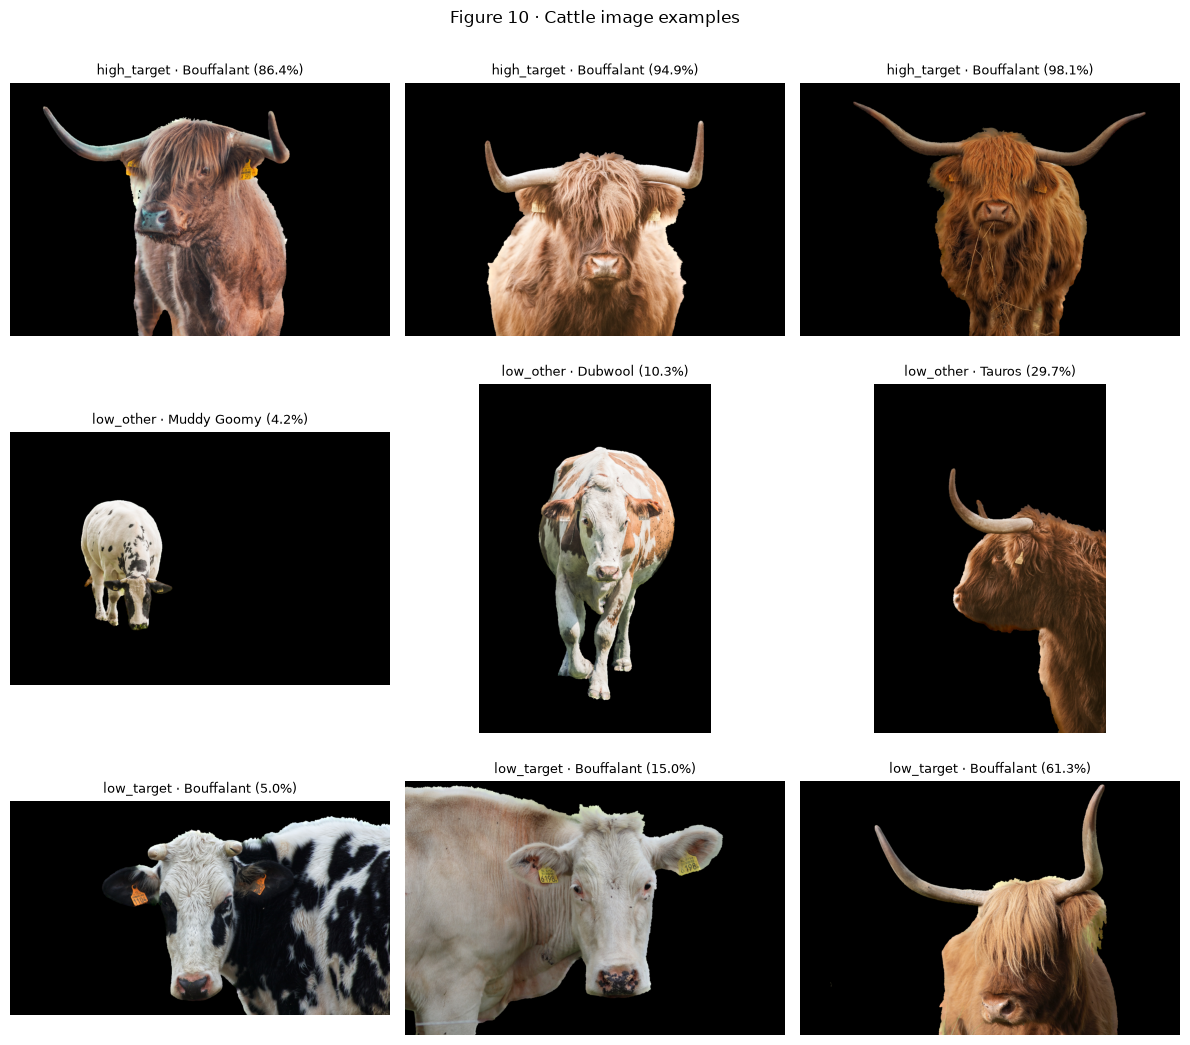

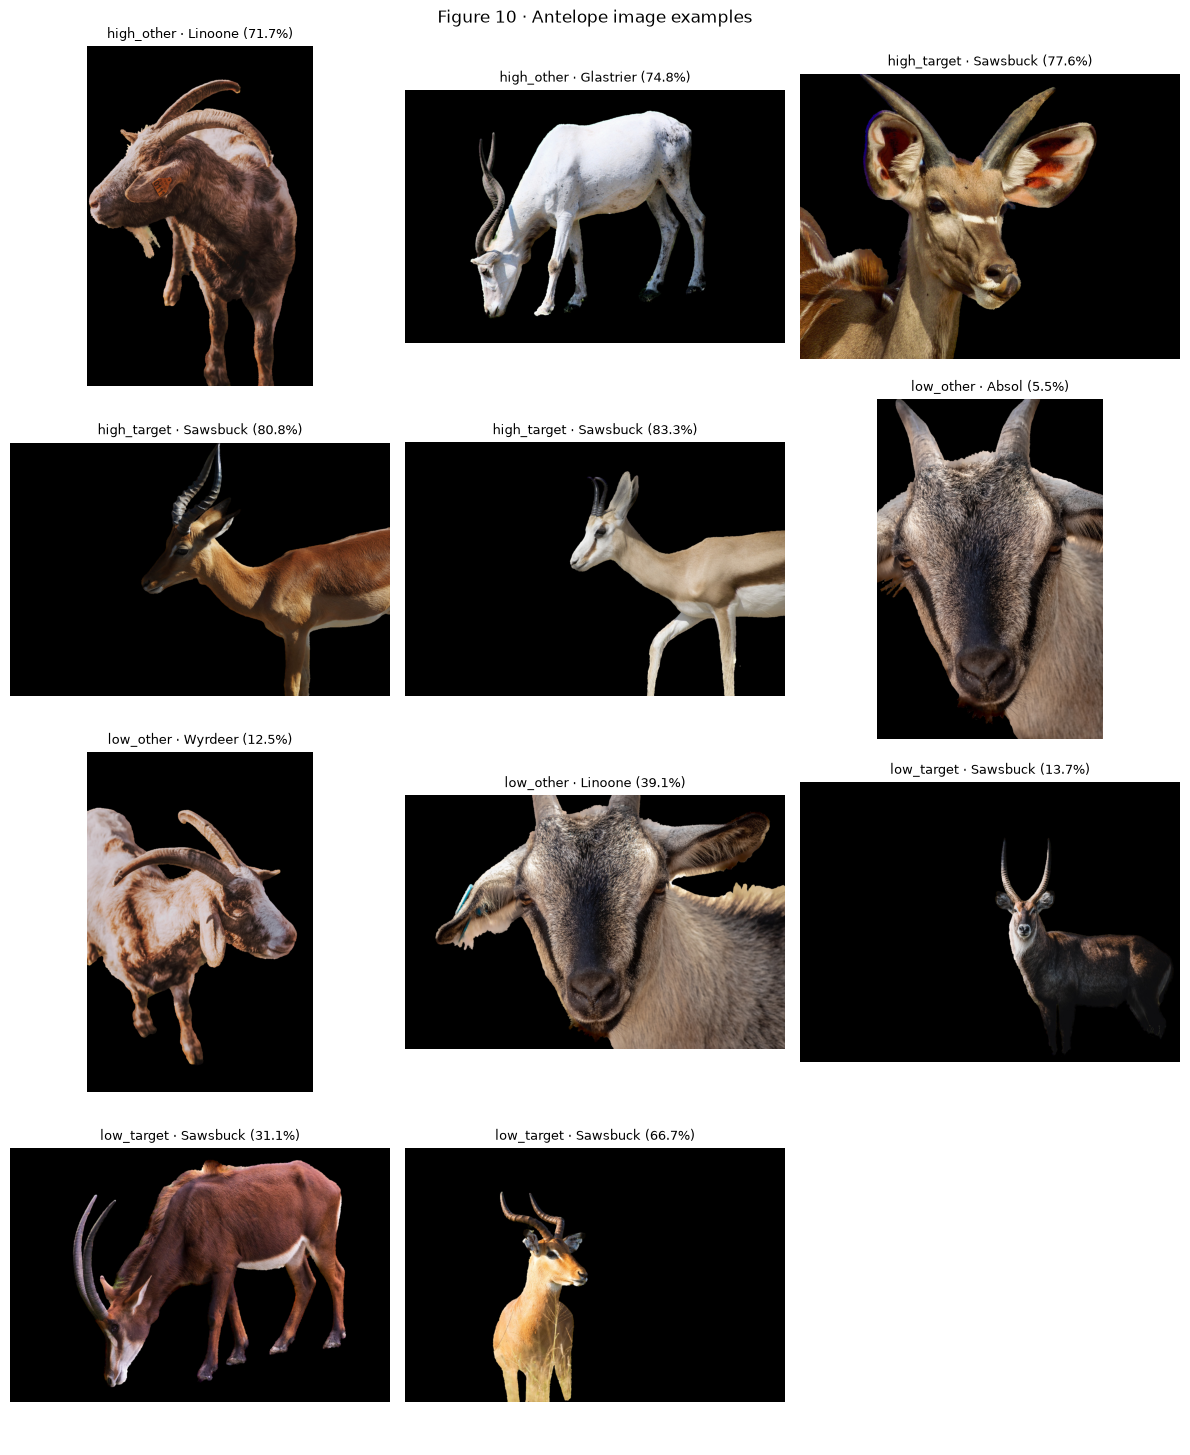

Selected 20 images for paired input tests.


In [6]:
from PIL import Image, ImageOps, ImageFilter

CASE_MODE='balanced'    # For exploratory case study. Set to 'all' to perturb all 180 images.
SAMPLE_PER_STRATUM=3

def select_rank_positions(frame,n):
    ordered=frame.sort_values(['confidence','source_row']).reset_index(drop=True)
    if len(ordered)<=n:return ordered
    pos=np.unique(np.round(np.linspace(.10,.90,n)*(len(ordered)-1)).astype(int))
    return ordered.iloc[pos]

chosen=[]
for animal,target in TARGET.items():
    g=subsets[animal]
    if CASE_MODE=='all':
        g=g.copy();g['stratum']='all';chosen.append(g);continue
    flag=g.predicted_pokemon.str.casefold().eq(target.casefold())
    masks={'high_target':g.high & flag,'low_target':~g.high & flag,
           'high_other':g.high & ~flag,'low_other':~g.high & ~flag}
    for name,mask in masks.items():
        pick=select_rank_positions(g.loc[mask],SAMPLE_PER_STRATUM).copy()
        if pick.empty:continue
        pick['stratum']=name
        chosen.append(pick)
cases=pd.concat(chosen,ignore_index=True).drop_duplicates('source_row')
cases=cases.sort_values(['animal_category','stratum','confidence']).reset_index(drop=True)
display(cases[['source_row','animal_category','stratum','predicted_pokemon','confidence','image_path']])
cases.to_csv(OUTDIR/'06_selected_image_cases.csv',index=False)

PROJECT_ROOT=CSV_PATH.parent.parent

def resolve_image(value,animal):
    if pd.isna(value) or not str(value).strip():return None
    p=Path(str(value).strip()).expanduser()
    candidates=[p,PROJECT_ROOT/p,PROJECT_ROOT/'dataset'/p,
                PROJECT_ROOT/'dataset'/'animal'/'fg_classified'/animal/p.name]
    if 'dataset' in p.parts:
        candidates.append(PROJECT_ROOT/Path(*p.parts[p.parts.index('dataset'):]))
    return next((v for v in candidates if v.is_file()),None)

cases['resolved_path']=[resolve_image(r.image_path,r.animal_category) for r in cases.itertuples(index=False)]
missing_paths=cases[cases.resolved_path.isna()]
if not missing_paths.empty:
    display(missing_paths[['source_row','animal_category','image_path']])
    raise FileNotFoundError('Some selected image paths are missing; check the paths or project root.')

for animal in TARGET:
    g=cases[cases.animal_category.eq(animal)]
    ncols=3;nrows=int(np.ceil(len(g)/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(12,3.7*nrows),squeeze=False)
    for ax in axes.ravel():ax.axis('off')
    for ax,r in zip(axes.ravel(),g.itertuples(index=False)):
        with Image.open(r.resolved_path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f'{r.stratum} · {r.predicted_pokemon} ({r.confidence:.1%})',fontsize=9)
    fig.suptitle(f'Figure 10 · {animal.title()} image examples')
    fig.tight_layout()
    fig.savefig(OUTDIR/f'07_cases_{animal}.png',dpi=160,bbox_inches='tight')
    plt.show()
print('Selected',len(cases),'images for paired input tests.')


## 6. Controlled changes to the input images


In [7]:
import torch
from transformers import AutoImageProcessor, AutoModelForImageClassification

MODEL_ID='imzynoxprince/pokemons-image-classifier-gen1-gen9'
DEVICE='mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
print('Loading pretrained checkpoint on',DEVICE)
processor=AutoImageProcessor.from_pretrained(MODEL_ID)
model=AutoModelForImageClassification.from_pretrained(MODEL_ID).to(DEVICE).eval()
id2label={int(k):str(v) for k,v in model.config.id2label.items()}
normalize_label=lambda s:re.sub(r'[^a-z0-9]+','',str(s).casefold())
label2id={normalize_label(v):k for k,v in id2label.items()}
for target in TARGET.values():
    if normalize_label(target) not in label2id:
        raise ValueError(f'Expected target label {target} not found in checkpoint.')

CONDITIONS=['original','grayscale','blur_1p5','blur_3p0']
def changed_image(path,condition):
    with Image.open(path) as im:
        original=ImageOps.exif_transpose(im).convert('RGB')
    if condition=='original':return original
    if condition=='grayscale':return ImageOps.grayscale(original).convert('RGB')
    if condition.startswith('blur_'):
        radius=float(condition.split('_')[1].replace('p','.'))
        return original.filter(ImageFilter.GaussianBlur(radius=radius))
    raise ValueError(condition)

def predict_batches(image_conditions,batch_size=8):
    answers=[]
    for start in range(0,len(image_conditions),batch_size):
        batch=image_conditions[start:start+batch_size]
        imgs=[changed_image(p,c) for p,c in batch]
        inputs=processor(images=imgs,return_tensors='pt')
        inputs={k:v.to(DEVICE) for k,v in inputs.items()}
        with torch.inference_mode():
            prob=torch.softmax(model(**inputs).logits.float(),dim=-1).cpu().numpy()
        answers.extend(prob)
    return answers

base_probs=predict_batches([(r.resolved_path,'original') for r in cases.itertuples(index=False)])
validation=[]
for r,p in zip(cases.itertuples(index=False),base_probs):
    new_label=id2label[int(np.argmax(p))]
    validation.append({'source_row':r.source_row,
        'same_top1':normalize_label(r.predicted_pokemon)==normalize_label(new_label),
        'absolute_confidence_difference':abs(r.confidence-float(p.max()))})
validation=pd.DataFrame(validation)
validation.to_csv(OUTDIR/'08_checkpoint_validation.csv',index=False)
print('Original top-1 replication:',f'{validation.same_top1.mean():.1%}',
      'max probability delta:',f'{validation.absolute_confidence_difference.max():.4f}')
if not validation.same_top1.all() or validation.absolute_confidence_difference.max() > .05:
    raise RuntimeError('Baseline mismatch: confirm original model, image paths and processor before continuing.')


/Users/tianbaby/Desktop/pokemon-ood/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 14:49:38.478000 48359 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading pretrained checkpoint on mps


Loading weights: 100%|██████████| 200/200 [00:00<00:00, 8314.94it/s]


Original top-1 replication: 100.0% max probability delta: 0.0000


In [8]:
items=[(r.resolved_path,c) for r in cases.itertuples(index=False) for c in CONDITIONS if c!='original']
new_probs=predict_batches(items)
by_key={(r.source_row,'original'):p for r,p in zip(cases.itertuples(index=False),base_probs)}
index=0
for r in cases.itertuples(index=False):
    for cond in CONDITIONS[1:]:
        by_key[(r.source_row,cond)]=new_probs[index]
        index+=1

rows=[]
for r in cases.itertuples(index=False):
    fixed_label=TARGET[r.animal_category]
    fixed_idx=label2id[normalize_label(fixed_label)]
    base_idx=int(by_key[(r.source_row,'original')].argmax())
    base_label=id2label[base_idx]
    for cond in CONDITIONS:
        p=by_key[(r.source_row,cond)]
        pred=id2label[int(p.argmax())]
        rows.append({'source_row':r.source_row,'animal_category':r.animal_category,
           'stratum':r.stratum,'condition':cond,'predicted_pokemon':pred,
           'top1_confidence':float(p.max()),'fixed_target':fixed_label,
           'target_probability':float(p[fixed_idx]),
           'top1_changed':normalize_label(pred)!=normalize_label(base_label)})
perturb=pd.DataFrame(rows)
perturb.to_csv(OUTDIR/'09_all_perturbation_predictions.csv',index=False)
print('Predictions:',len(perturb),'from',len(cases),'distinct images')
display(perturb.head(8).round(4))


Predictions: 80 from 20 distinct images


,source_row,animal_category,stratum,condition,predicted_pokemon,top1_confidence,fixed_target,target_probability,top1_changed
0,146,antelope,high_other,original,Linoone,0.7173,Sawsbuck,0.0006,False
1,146,antelope,high_other,grayscale,Linoone,0.6866,Sawsbuck,0.0006,False
2,146,antelope,high_other,blur_1p5,Linoone,0.6992,Sawsbuck,0.0006,False
3,146,antelope,high_other,blur_3p0,Linoone,0.6625,Sawsbuck,0.0008,False
4,100,antelope,high_other,original,Glastrier,0.7478,Sawsbuck,0.0046,False
5,100,antelope,high_other,grayscale,Glastrier,0.4548,Sawsbuck,0.0320,False
6,100,antelope,high_other,blur_1p5,Glastrier,0.7527,Sawsbuck,0.0045,False
7,100,antelope,high_other,blur_3p0,Glastrier,0.7508,Sawsbuck,0.0044,False


## 7. Visualizing input-response behavior



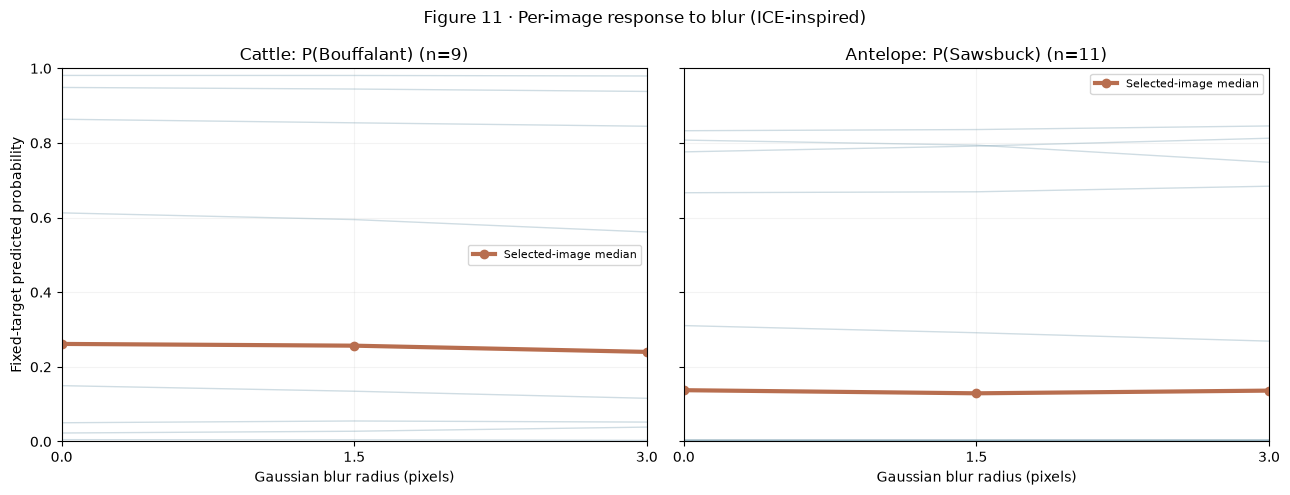

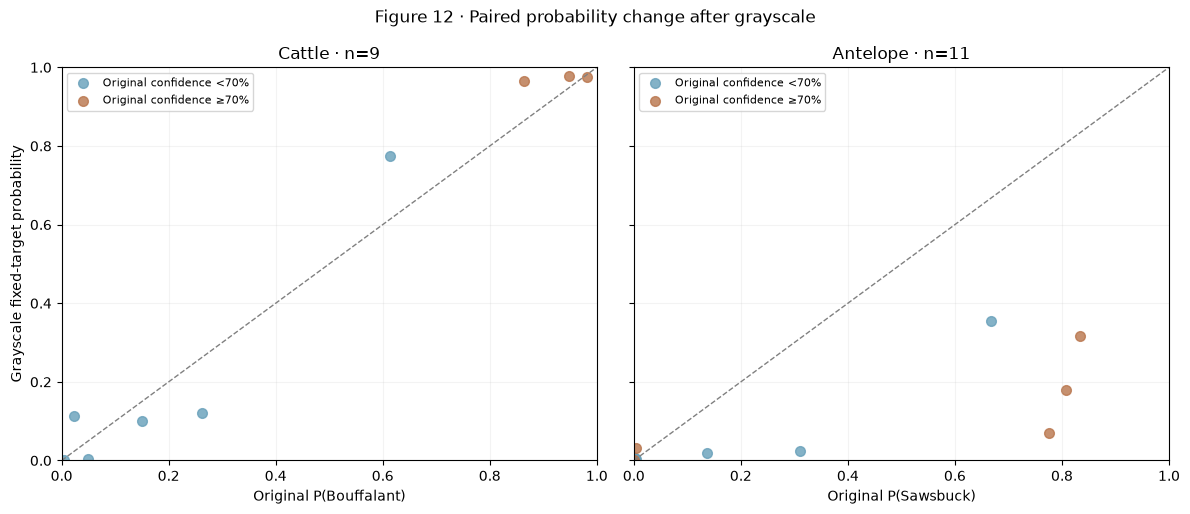

,animal_category,condition,n,median_delta,top1_switches,switch_rate_pct
0,antelope,blur_1p5,11,0.000,0,0.000
1,antelope,blur_3p0,11,0.000,1,9.091
2,antelope,grayscale,11,-0.118,5,45.455
3,cattle,blur_1p5,9,-0.004,0,0.000
4,cattle,blur_3p0,9,-0.011,0,0.000
5,cattle,grayscale,9,-0.003,3,33.333


In [9]:
blur=perturb[perturb.condition.isin(['original','blur_1p5','blur_3p0'])].copy()
blur['radius']=blur.condition.map({'original':0.,'blur_1p5':1.5,'blur_3p0':3.})
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
for ax,(animal,target) in zip(axes,TARGET.items()):
    p=blur[blur.animal_category.eq(animal)].pivot(index='source_row',columns='radius',values='target_probability')
    p=p.reindex(columns=[0.,1.5,3.])
    for _,values in p.iterrows():ax.plot(p.columns,values,alpha=.35,lw=1,color='#779DAF')
    ax.plot(p.columns,p.median().values,color='#B86E4F',lw=3,marker='o',label='Selected-image median')
    ax.set(title=f'{animal.title()}: P({target}) (n={len(p)})',xlabel='Gaussian blur radius (pixels)',
           xlim=(0,3),xticks=[0,1.5,3.],ylim=(0,1))
    ax.legend(fontsize=8);ax.grid(alpha=.15)
axes[0].set_ylabel('Fixed-target predicted probability')
fig.suptitle('Figure 11 · Per-image response to blur (ICE-inspired)')
fig.tight_layout()
fig.savefig(OUTDIR/'10_blur_response_curves.png',dpi=180,bbox_inches='tight')
plt.show()

wide=perturb.pivot(index='source_row',columns='condition',values='target_probability')
meta=cases[['source_row','animal_category','high']]
gray=wide[['original','grayscale']].reset_index().merge(meta,on='source_row',validate='one_to_one')
fig,axes=plt.subplots(1,2,figsize=(12,5.2),sharex=True,sharey=True)
for ax,(animal,target) in zip(axes,TARGET.items()):
    g=gray[gray.animal_category.eq(animal)]
    for flag,color,label in [(False,'#669FB9','Original confidence <70%'),(True,'#B8744B','Original confidence ≥70%')]:
        s=g[g.high.eq(flag)]
        ax.scatter(s['original'],s['grayscale'],s=49,alpha=.8,color=color,label=label)
    ax.plot([0,1],[0,1],color='gray',lw=1,ls='--')
    ax.set(title=f'{animal.title()} · n={len(g)}',xlabel=f'Original P({target})',xlim=(0,1),ylim=(0,1))
    ax.legend(fontsize=8);ax.grid(alpha=.15)
axes[0].set_ylabel('Grayscale fixed-target probability')
fig.suptitle('Figure 12 · Paired probability change after grayscale')
fig.tight_layout()
fig.savefig(OUTDIR/'11_grayscale_paired_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

original=wide[['original']].rename(columns={'original':'base_target_prob'}).reset_index()
change=perturb[perturb.condition.ne('original')].merge(original,on='source_row',validate='many_to_one')
change['delta_target_prob']=change.target_probability-change.base_target_prob
stats=(change.groupby(['animal_category','condition'],as_index=False)
    .agg(n=('source_row','nunique'),median_delta=('delta_target_prob','median'),
         mean_delta=('delta_target_prob','mean'),top1_switches=('top1_changed','sum'),
         switch_rate=('top1_changed','mean')))
stats['switch_rate_pct']=100*stats.switch_rate
stats.to_csv(OUTDIR/'12_perturbation_summary.csv',index=False)
display(stats[['animal_category','condition','n','median_delta','top1_switches','switch_rate_pct']].round(3))
